# Radius sensitivity (ECNP)

In [4]:
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import os
import numpy as np
import squidpy as sq
import anndata
import pandas as pd
import seaborn as sns
import tqdm
from scipy.stats import spearmanr
import scFates as scf
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, SAMPLES_SYMBOLS, WORK_PATH, SAMPLE_COLORS
import Xenium_5K_IPF_def_rev as rev

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
min_threshold = 5

In [5]:
REV_PATH=f"{WORK_PATH}Revision/101/"
os.makedirs(REV_PATH, exist_ok=True)

In [6]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")
celltype_csv = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = adata[celltype_csv.index].copy()
adata.obs = pd.merge(adata.obs, celltype_csv[["cell_type", "subtype"]], left_index=True, right_index=True)
sub_adata = adata[adata.obs["cell_type"] == "Epithelial"].copy()

In [7]:
distance = [40, 60, 80, 100, 120]

## Epithelial-centered neighborhood profiling of other distances

In [8]:
coords = adata.obsm["spatial"].copy()

In [9]:
for d in distance:
    save_name = f"{REV_PATH}EcNP_score_{d}.csv"
    
    if os.path.isfile(save_name):
        print(f"radius = {d} already done!")
    
    else:
        score_list = []
        for idx in tqdm.tqdm(range(len(sub_adata))):
            # Obtain the coordinates of the central cell
            target_coord = sub_adata.obsm["spatial"][idx]
        
            # Distance calculation
            distances = np.linalg.norm(coords - target_coord, axis=1)
            
            # Neighbor cells within a certain distance
            mask = (distances <= d) 
            neighbor_indices = np.where(mask)[0]
        
            neighbor_distances = distances[neighbor_indices]
            neighbor_subtypes = adata.obs["subtype"].values[neighbor_indices]
            
            # Score calculation for each subtype
            subtype_score = pd.Series(data=neighbor_subtypes).value_counts()
            
            # Scores for all subtypes
            full_score = {sub: 0.0 for sub in ALL_SUBTYPE_LIST}
            full_score.update(subtype_score.to_dict())
        
            score_list.append(full_score)
        # Output（Dataframe: epithelial subtypes × all subtypes）
        score_df = pd.DataFrame(score_list, index=sub_adata.obs_names)
        
        score_df.to_csv(save_name, encoding="utf-8-sig")


radius = 40 already done!
radius = 60 already done!
radius = 80 already done!
radius = 100 already done!
radius = 120 already done!


## Count neighbor cells

In [10]:
count_dfs = []
for d in distance:
    score_df = pd.read_csv(f"{REV_PATH}EcNP_score_{d}.csv", index_col=0)
    count_df = pd.DataFrame([sub_adata.obs["sample"], score_df.sum(axis=1)], index=["sample", "counts"]).T
    count_df["sample"] = pd.Categorical(count_df["sample"], categories=SAMPLES_SYMBOLS)
    count_dfs.append(count_df)

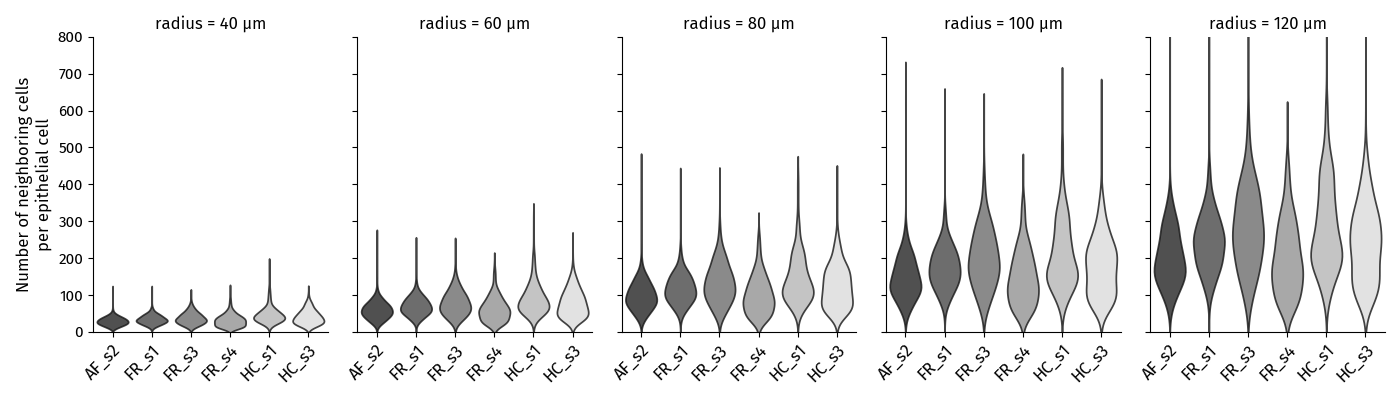

In [11]:
fig, axes = plt.subplots(1,5,figsize=(14,4))

for n, (cdf, d, ax) in enumerate(zip(count_dfs, distance, axes)):
    sns.violinplot(cdf, x="sample", y="counts", inner=None, ax=ax, color="grey", bw_adjust=2, hue="sample",palette="grey", alpha=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(0,800)
    ax.set_xticks(ticks=ax.get_xticks(), labels=ax.get_xticklabels(), fontsize=12, rotation=45, rotation_mode='anchor', ha="right", va="top")
    ax.set_title(f"radius = {d} µm")
    if n == 0:       
        ax.set_ylabel("Number of neighboring cells\nper epithelial cell", fontsize=12)
        ax.tick_params("y", labelsize=11)
    else:
        ax.set_yticks(ticks=ax.get_yticks(), labels=[])

fig.tight_layout()
fig.savefig(f"{REV_PATH}101_neighbor_cell_counts.png", dpi=300)

## Clustering for each distance

In [5]:
# for d in [40, 60, 100, 120]:
#     score_df = pd.read_csv(f"{REV_PATH}EcNP_score_{d}.csv", index_col=0)
#     score_adata = anndata.AnnData(
#         X=score_df.values.copy(),
#         obs=sub_adata.obs.copy(),
#         obsm={"spatial": sub_adata.obsm["spatial"].copy()},
#         var=pd.DataFrame(index=score_df.columns)
#     )
#     score_adata.raw = score_adata.copy()
#     sc.pp.filter_cells(score_adata, min_counts=5)
#     sc.pp.normalize_total(score_adata, target_sum=1e4)
#     sc.pp.log1p(score_adata)
#     sc.pp.pca(score_adata, n_comps=5)
#     sc.pp.neighbors(score_adata, n_neighbors=50, use_rep="X_pca")
#     sc.tl.leiden(score_adata, flavor="igraph", directed=False, resolution=0.25)
#     score_adata.write(f"{REV_PATH}EcNP_{d}_clustering.h5ad")

filtered out 142 cells that have less than 5 counts
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=5
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:31)
running Leiden clustering
    finished: found 7 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:03)
filtered out 27 cells that have less than 5 counts
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=5
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:10)
running Leiden clustering
    finished: found 9 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:03)
filtered out 12 cells that 

In [12]:
clustering_dict = {}
for d in [40, 60, 100, 120]:
    temp_adata = sc.read_h5ad(f"{REV_PATH}EcNP_{d}_clustering.h5ad")
    clustering_dict[d] = temp_adata.obs["leiden"]

In [13]:
adata_80 = sc.read_h5ad(f"{WORK_PATH}AnnData/EcNP.h5ad")
class_80 = adata_80.obs["EcNP"]

In [14]:
for d in [40, 60, 100, 120]:
    adata_80.obs[f"leiden_{d}"] = clustering_dict[d]

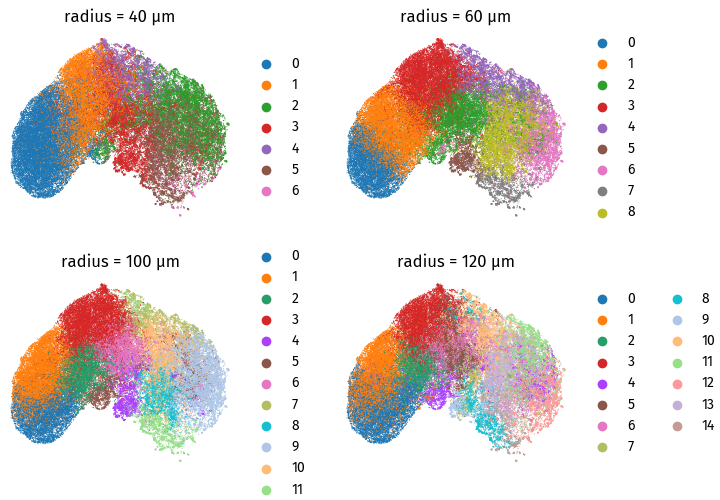

In [15]:
fig, axes = plt.subplots(2,2,figsize=(7.2,5))
fig.subplots_adjust(left=0, right=0.8, bottom=0.05, top=0.95, wspace=0.4)
axes = axes.flatten()

for d, ax, in zip([40, 60, 100, 120], axes):
    sc.pl.umap(adata_80, color=f"leiden_{d}", s=2, ax=ax, show=False, na_in_legend=False, na_color="black")
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"radius = {d} µm")

fig.savefig(f"{REV_PATH}EcNP_umap_leiden_on_d80.png", dpi=500, format="png", bbox_inches=None)

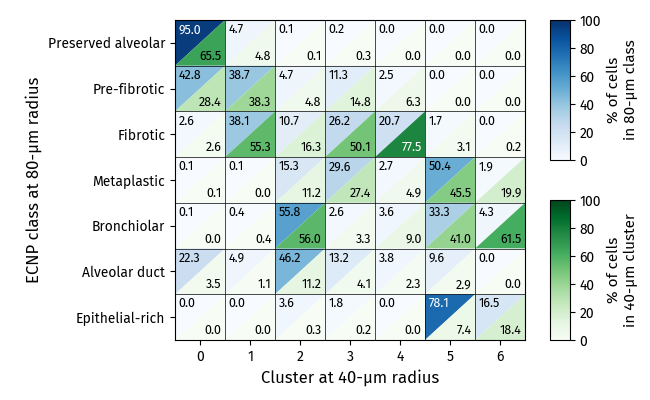

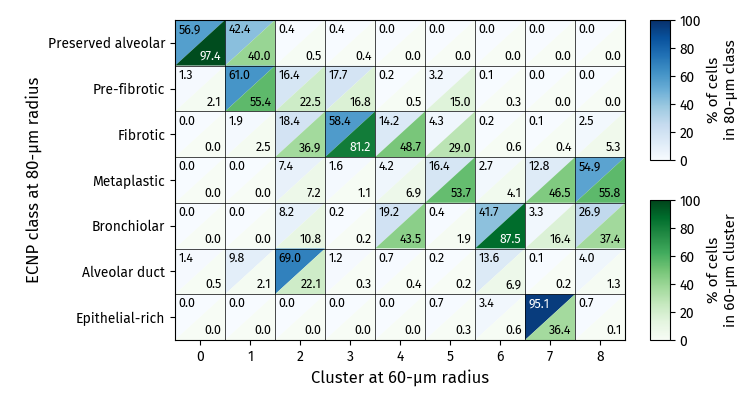

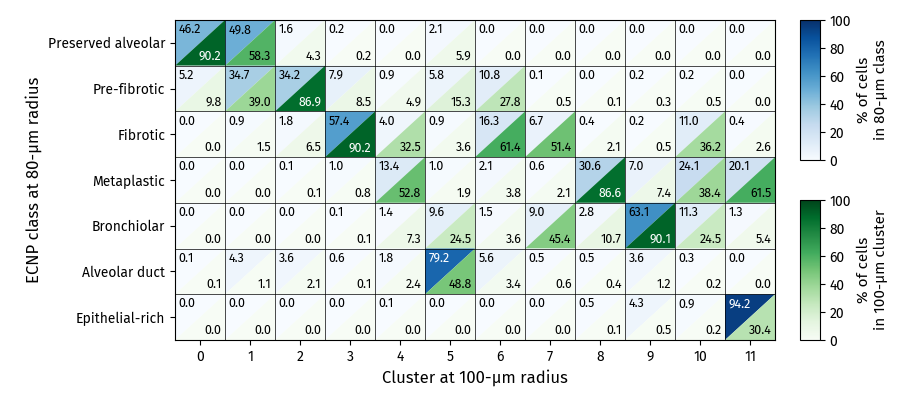

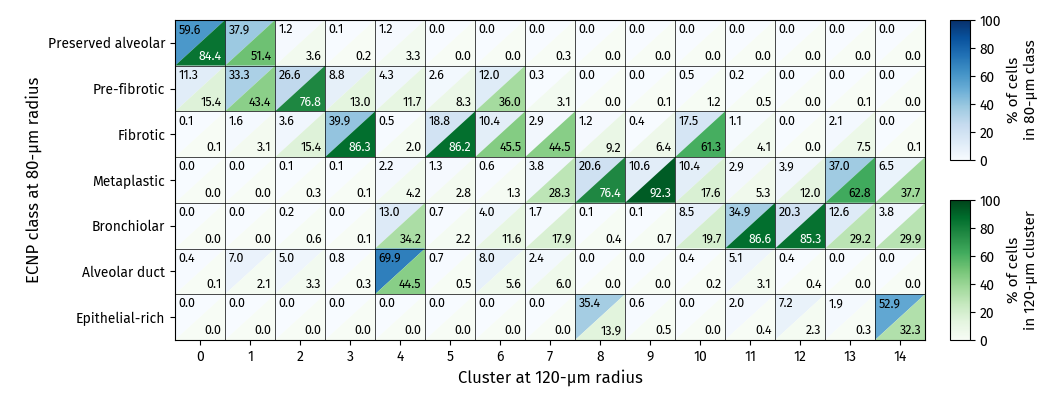

In [16]:
for d in [40, 60, 100, 120]:
    temp = pd.concat([class_80.rename("class_80"), clustering_dict[d].rename("cluster_alt")], axis=1, join="inner").dropna()
    overlap_mat = pd.crosstab(temp["class_80"], temp["cluster_alt"], normalize="index") * 100
    overlap_col = pd.crosstab(temp["class_80"], temp["cluster_alt"], normalize="columns") * 100
    
    R, C = overlap_mat.shape
    
    fig, ax = plt.subplots(figsize=((C+6)*0.5, 4))
    fig.subplots_adjust(left=3.5/(C+6), top=0.95, bottom=0.15, right=1-2.5/(C+6))
    
    norm = matplotlib.colors.Normalize(vmin=0, vmax=100)
    sm_b = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
    sm_g = plt.cm.ScalarMappable(cmap="Greens", norm=norm)
    
    
    ax.set_ylim(0, R)
    ax.set_xlim(0, C)
    for r in range(R):
        for c in range(C):
            
            p_1 = matplotlib.patches.Polygon(xy=[(c, R-r), (c+1, R-r), (c, R-r-1)],
                                             fc=sm_b.to_rgba(overlap_mat.iloc[r,c], bytes=False), ec="none")
            p_2 = matplotlib.patches.Polygon(xy=[(c+1, R-r-1), (c+1, R-r), (c, R-r-1)],
                                             fc=sm_g.to_rgba(overlap_col.iloc[r,c], bytes=False), ec="none")
            spc= 0.07
            if overlap_mat.iloc[r,c] < 70:
                ax.text(s=format(overlap_mat.iloc[r,c], ".1f"), x=c+spc, y=R-r-spc, ha="left", va="top", c="black", fontsize=9)
            else:
                ax.text(s=format(overlap_mat.iloc[r,c], ".1f"), x=c+spc, y=R-r-spc, ha="left", va="top", c="white", fontsize=9)
                
            if overlap_col.iloc[r,c] < 70:
                ax.text(s=format(overlap_col.iloc[r,c], ".1f"), x=c+1-spc, y=R-r-1+spc, ha="right", va="bottom", c="black", fontsize=9)
            else:
                ax.text(s=format(overlap_col.iloc[r,c], ".1f"), x=c+1-spc, y=R-r-1+spc, ha="right", va="bottom", c="white", fontsize=9)
                
            ax.add_patch(p_1)
            ax.add_patch(p_2)
    
    for r in range(R-1):
        ax.axhline(y=r+1, c="black", lw=0.5)
    for c in range(C-1):
        ax.axvline(x=c+1, c="black", lw=0.5)
    
    ax.set_yticks(ticks=[n+0.5 for n in range(R)], labels=overlap_mat.index[::-1])
    ax.set_xticks(ticks=[n+0.5 for n in range(C)], labels=overlap_mat.columns)
    
    cax_b = fig.add_axes([1-2/(C+6),0.6,0.4/(C+6),0.35])
    cax_g = fig.add_axes([1-2/(C+6),0.15, 0.4/(C+6),0.35])
    cbar_b = fig.colorbar(sm_b, cax=cax_b, orientation='vertical', pad=0.05)
    cbar_g = fig.colorbar(sm_g, cax=cax_g, orientation='vertical', pad=0.05)
    cax_b.set_ylabel("% of cells\nin 80-µm class", fontsize=11)
    cax_g.set_ylabel(f"% of cells\nin {d}-µm cluster", fontsize=11)
    cax_b.tick_params(labelsize=10)
    cax_g.tick_params(labelsize=10)
    
    ax.set_xlabel(f"Cluster at {d}-µm radius", fontsize=12)
    ax.set_ylabel("ECNP class at 80-µm radius", fontsize=12)
    
    fig.savefig(f"{REV_PATH}101_class_clustering_heatmap_d{d}.png", dpi=500)

In [17]:
def normalize_composition(df):
    valid = df.sum(axis=1) > 0
    out = df.loc[valid].copy()
    out = out.div(out.sum(axis=1), axis=0)

    return out

def make_centroid(score_df, labels):
    prop = normalize_composition(score_df)
    common_idx = prop.index.intersection(labels.dropna().index)

    prop = prop.loc[common_idx]
    labels = labels.loc[common_idx]

    centroid = (
        prop
        .assign(_label=labels.values)
        .groupby("_label")
        .mean()
    )

    centroid = centroid.div(centroid.sum(axis=1), axis=0)

    return centroid

In [18]:
score_df_80 = pd.read_csv(f"{REV_PATH}EcNP_score_80.csv", index_col=0)

In [19]:
centroid_80 = make_centroid(score_df_80, class_80)

/tmp/ipykernel_2351/2583373088.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("_label")


In [20]:
def hellinger_centroid_matrix(ref_centroid, alt_centroid):
    common_cols = ref_centroid.columns.intersection(alt_centroid.columns)

    ref = ref_centroid[common_cols].copy()
    alt = alt_centroid[common_cols].copy()

    ref = ref.div(ref.sum(axis=1), axis=0)
    alt = alt.div(alt.sum(axis=1), axis=0)

    dist_mat = pd.DataFrame(index=ref.index, columns=alt.index, dtype=float)

    for ref_label in ref.index:
        p = ref.loc[ref_label].values

        for alt_label in alt.index:
            q = alt.loc[alt_label].values

            dist_mat.loc[ref_label, alt_label] = np.sqrt(
                np.sum((np.sqrt(p) - np.sqrt(q)) ** 2) / 2
            )

    return dist_mat

In [21]:
H_centroid_dict = {}

for d in [40, 60, 100, 120]:
    score_df = pd.read_csv(f"{REV_PATH}EcNP_score_{d}.csv", index_col=0)

    cluster_alt = clustering_dict[d]

    centroid_alt = make_centroid(
        score_df,
        cluster_alt
    )

    H_centroid_dict[d] = hellinger_centroid_matrix(
        centroid_80,
        centroid_alt
    )

/tmp/ipykernel_2351/2583373088.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("_label")
/tmp/ipykernel_2351/2583373088.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("_label")
/tmp/ipykernel_2351/2583373088.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("_label")
/tmp/ipykernel_2351/2583373088.py:18: FutureWarning: The default of observed=False is deprecated and will be change

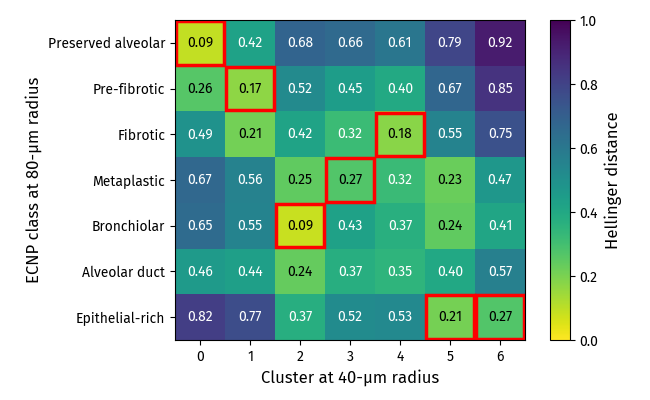

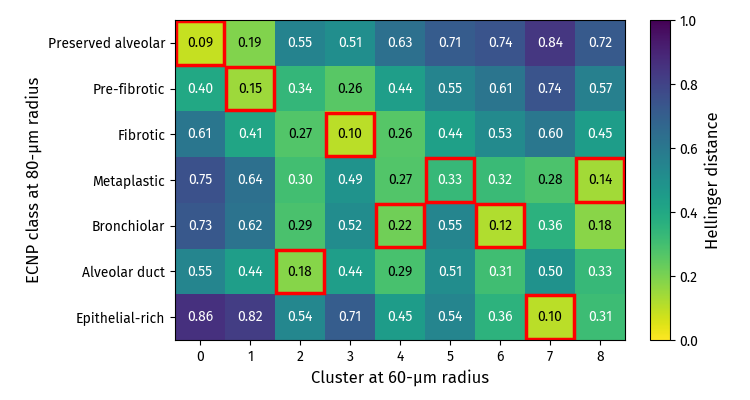

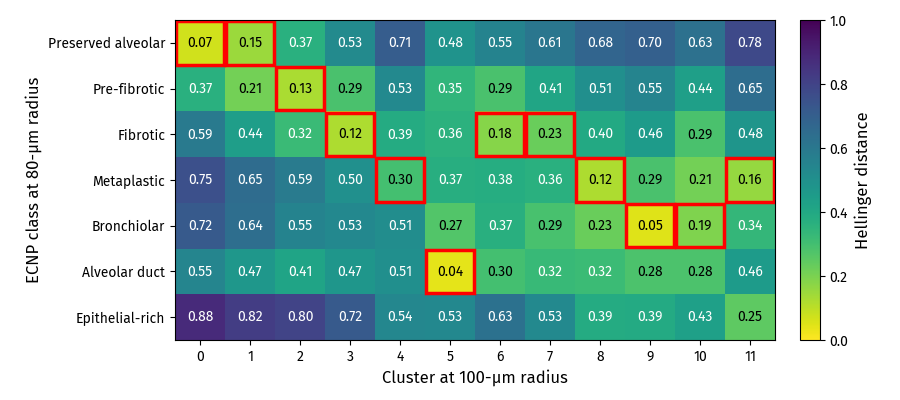

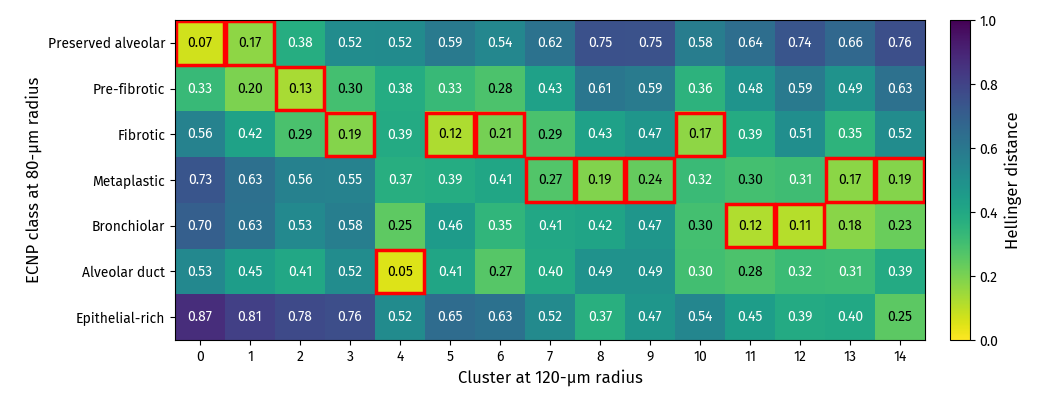

In [22]:
spc_r=0.025
for d in [40, 60, 100, 120]:
    R, C = H_centroid_dict[d].shape
    
    fig, ax = plt.subplots(figsize=((C+6)*0.5, 4))
    fig.subplots_adjust(left=3.5/(C+6), top=0.95, bottom=0.15, right=1-2.5/(C+6))
    
    norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
    sm_v = plt.cm.ScalarMappable(cmap="viridis_r", norm=norm)
       
    ax.set_ylim(0, R)
    ax.set_xlim(0, C)

    for r in range(R):
        for c in range(C):
            
            rec = matplotlib.patches.Rectangle(xy=(c, R-r-1), width=1, height=1,
                                               fc=sm_v.to_rgba(H_centroid_dict[d].iloc[r,c], bytes=False), ec="none")
            if H_centroid_dict[d].iloc[r,c] > 0.3:
                ax.text(s=format(H_centroid_dict[d].iloc[r,c], ".2f"), x=c+0.5, y=R-r-0.5, ha="center", va="center", c="white", fontsize=10)
            else:
                ax.text(s=format(H_centroid_dict[d].iloc[r,c], ".2f"), x=c+0.5, y=R-r-0.5, ha="center", va="center", c="black", fontsize=10)
                
            ax.add_patch(rec)
    ax.set_yticks(ticks=[n+0.5 for n in range(R)], labels=H_centroid_dict[d].index[::-1])
    ax.set_xticks(ticks=[n+0.5 for n in range(C)], labels=H_centroid_dict[d].columns)
    
    cax_v = fig.add_axes([1-2/(C+6),0.15,0.4/(C+6),0.8])
    cbar_v = fig.colorbar(sm_v, cax=cax_v, orientation='vertical', pad=0.05)
    cax_v.set_ylabel("Hellinger distance", fontsize=12)
    cax_v.tick_params(labelsize=10)

    ax.set_xlabel(f"Cluster at {d}-µm radius", fontsize=12)
    ax.set_ylabel("ECNP class at 80-µm radius", fontsize=12)

    for cc, ii in H_centroid_dict[d].idxmin(axis=0).items():
        rr = H_centroid_dict[d].index.get_loc(ii)

        rec = matplotlib.patches.Rectangle(xy=(int(cc)+spc_r, R-rr-1+spc_r), width=1-2*spc_r, height=1-2*spc_r, 
                                           fc="none", ec="red", lw=2.5)
        ax.add_patch(rec)
    fig.savefig(f"{REV_PATH}101_class_clustering_hellinger_distance_d{d}.png", dpi=500)

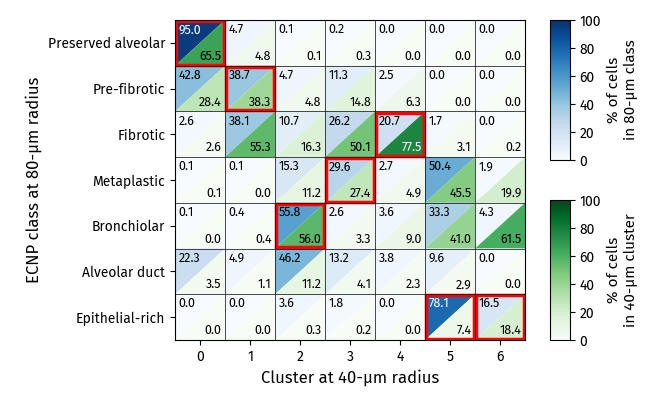

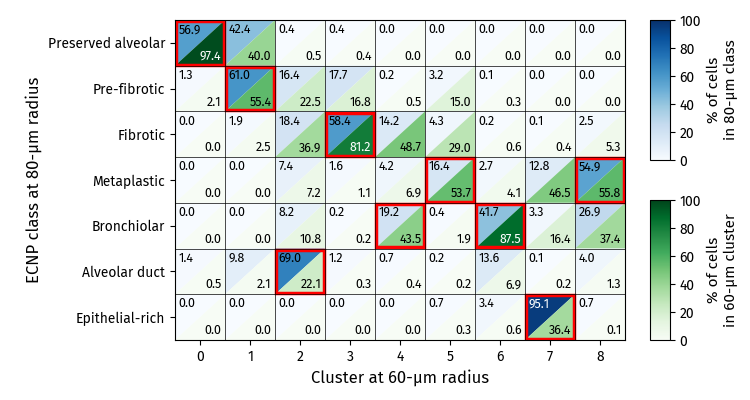

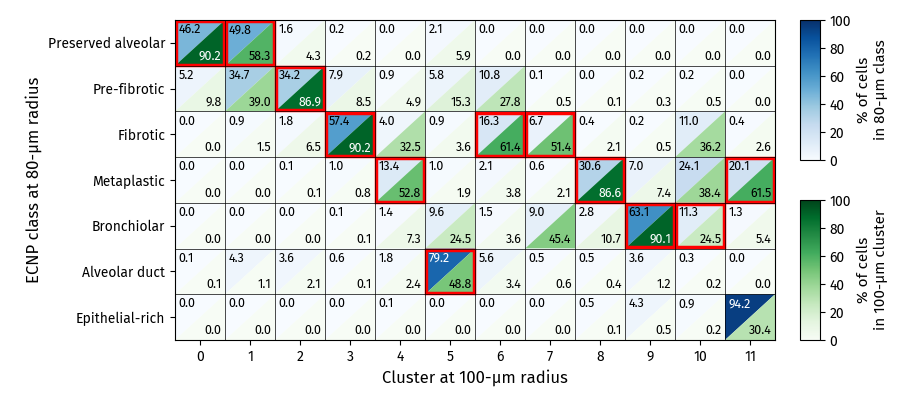

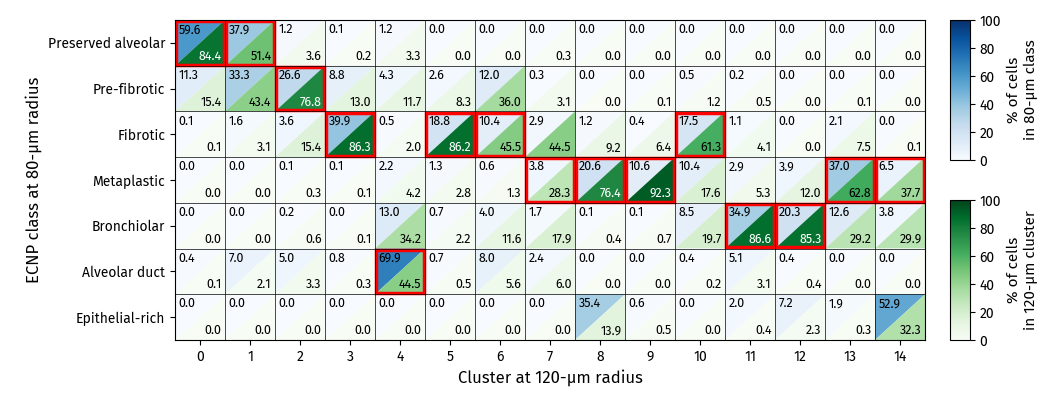

In [23]:
for d in [40, 60, 100, 120]:
    temp = pd.concat([class_80.rename("class_80"), clustering_dict[d].rename("cluster_alt")], axis=1, join="inner").dropna()
    overlap_mat = pd.crosstab(temp["class_80"], temp["cluster_alt"], normalize="index") * 100
    overlap_col = pd.crosstab(temp["class_80"], temp["cluster_alt"], normalize="columns") * 100
    
    R, C = overlap_mat.shape
    
    fig, ax = plt.subplots(figsize=((C+6)*0.5, 4))
    fig.subplots_adjust(left=3.5/(C+6), top=0.95, bottom=0.15, right=1-2.5/(C+6))
    
    norm = matplotlib.colors.Normalize(vmin=0, vmax=100)
    sm_b = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
    sm_g = plt.cm.ScalarMappable(cmap="Greens", norm=norm)
    
    
    ax.set_ylim(0, R)
    ax.set_xlim(0, C)
    for r in range(R):
        for c in range(C):
            
            p_1 = matplotlib.patches.Polygon(xy=[(c, R-r), (c+1, R-r), (c, R-r-1)],
                                             fc=sm_b.to_rgba(overlap_mat.iloc[r,c], bytes=False), ec="none")
            p_2 = matplotlib.patches.Polygon(xy=[(c+1, R-r-1), (c+1, R-r), (c, R-r-1)],
                                             fc=sm_g.to_rgba(overlap_col.iloc[r,c], bytes=False), ec="none")
            spc= 0.07
            if overlap_mat.iloc[r,c] < 70:
                ax.text(s=format(overlap_mat.iloc[r,c], ".1f"), x=c+spc, y=R-r-spc, ha="left", va="top", c="black", fontsize=9)
            else:
                ax.text(s=format(overlap_mat.iloc[r,c], ".1f"), x=c+spc, y=R-r-spc, ha="left", va="top", c="white", fontsize=9)
                
            if overlap_col.iloc[r,c] < 70:
                ax.text(s=format(overlap_col.iloc[r,c], ".1f"), x=c+1-spc, y=R-r-1+spc, ha="right", va="bottom", c="black", fontsize=9)
            else:
                ax.text(s=format(overlap_col.iloc[r,c], ".1f"), x=c+1-spc, y=R-r-1+spc, ha="right", va="bottom", c="white", fontsize=9)
                
            ax.add_patch(p_1)
            ax.add_patch(p_2)
    
    for r in range(R-1):
        ax.axhline(y=r+1, c="black", lw=0.5)
    for c in range(C-1):
        ax.axvline(x=c+1, c="black", lw=0.5)
    
    ax.set_yticks(ticks=[n+0.5 for n in range(R)], labels=overlap_mat.index[::-1])
    ax.set_xticks(ticks=[n+0.5 for n in range(C)], labels=overlap_mat.columns)
    
    cax_b = fig.add_axes([1-2/(C+6),0.6,0.4/(C+6),0.35])
    cax_g = fig.add_axes([1-2/(C+6),0.15, 0.4/(C+6),0.35])
    cbar_b = fig.colorbar(sm_b, cax=cax_b, orientation='vertical', pad=0.05)
    cbar_g = fig.colorbar(sm_g, cax=cax_g, orientation='vertical', pad=0.05)
    cax_b.set_ylabel("% of cells\nin 80-µm class", fontsize=11)
    cax_g.set_ylabel(f"% of cells\nin {d}-µm cluster", fontsize=11)
    cax_b.tick_params(labelsize=10)
    cax_g.tick_params(labelsize=10)
    
    ax.set_xlabel(f"Cluster at {d}-µm radius", fontsize=12)
    ax.set_ylabel("ECNP class at 80-µm radius", fontsize=12)

    for cc, ii in H_centroid_dict[d].idxmin(axis=0).items():
        rr = H_centroid_dict[d].index.get_loc(ii)

        rec = matplotlib.patches.Rectangle(xy=(int(cc)+spc_r, R-rr-1+spc_r), width=1-2*spc_r, height=1-2*spc_r, 
                                           fc="none", ec="red", lw=2.5)
        ax.add_patch(rec)
    
    fig.savefig(f"{REV_PATH}101_class_clustering_heatmap_d{d}_anotated.png", dpi=500)

In [24]:
label_dict= {}
for d in [40, 60, 100, 120]:
    label_dict[d] = H_centroid_dict[d].idxmin(axis=0)

In [25]:
for n,d in enumerate(distance):
    if d != 80:
        sub_adata.obs[f"leiden_{d}"]=clustering_dict[d]
        sub_adata.obs[f"near_class_{d}"]=sub_adata.obs[f"leiden_{d}"].map(label_dict[d])
        sub_adata.obs[f"near_class_{d}"]=pd.Categorical(sub_adata.obs[f"near_class_{d}"], categories=adata_80.obs["EcNP"].cat.categories, ordered=True)
        sub_adata.uns[f"near_class_{d}_colors"]=adata_80.uns["EcNP_colors"]
    else: 
        sub_adata.obs["EcNP"] = adata_80.obs["EcNP"]
        sub_adata.uns["EcNP_colors"]=adata_80.uns["EcNP_colors"]

/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[

Bbox(x0=0.05, y0=0.8196914637203692, x1=0.21379310344827585, y1=0.944594250565345)
Bbox(x0=0.05690299532900912, y0=0.6514285714285715, x1=0.20689010811926672, y1=0.7871428571428571)


/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _ca

Bbox(x0=0.05, y0=0.49415451113058595, x1=0.21379310344827585, y1=0.6187026317265569)
Bbox(x0=0.05, y0=0.32692336675113143, x1=0.21379310344827585, y1=0.46021949039172566)


/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[

Bbox(x0=0.05578997567136941, y0=0.16285714285714292, x1=0.20800312777690644, y1=0.2985714285714286)


/home/s_nakamura/test_env/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/s_nakamura/test_env/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
 

Bbox(x0=0.05, y0=0.0015011024753021907, x1=0.21379310344827585, y1=0.1342131832389837)


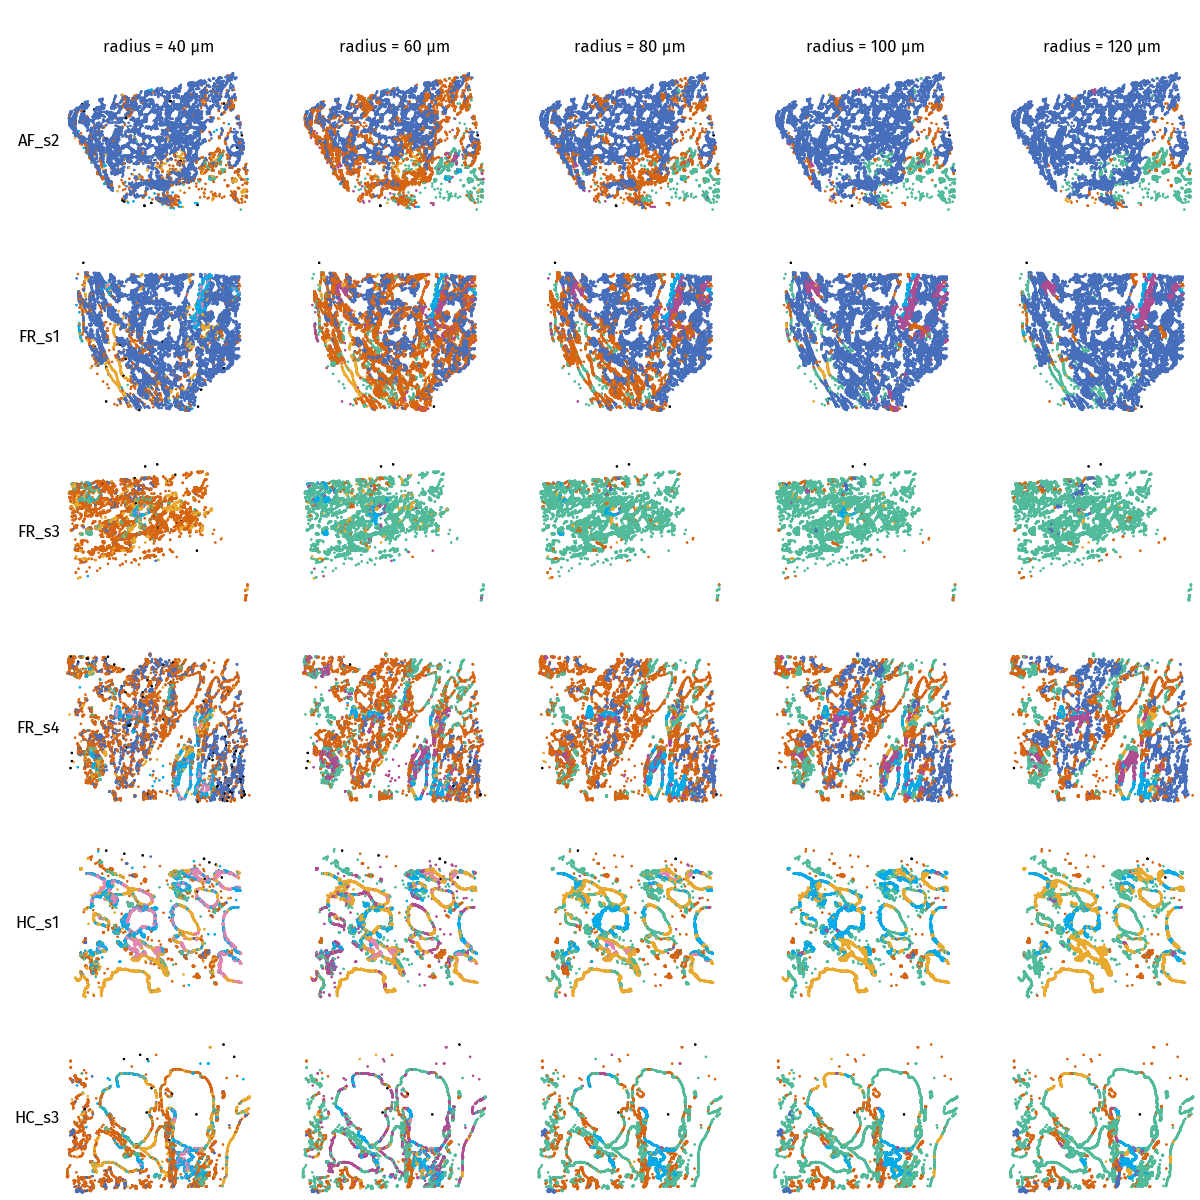

In [26]:
fig, axes = plt.subplots(6,5, figsize=(12,12))
fig.subplots_adjust(left=0.05, top=0.95, bottom=0, right=1)
axes = axes.flatten()
sl =sub_adata.obs["sample"].cat.categories
cl=["near_class_40", "near_class_60", "EcNP", "near_class_100", "near_class_120"]
ti=[f"radius = {d} µm" for d in distance]
for n, ax in enumerate(axes):
    sq.pl.spatial_scatter(sub_adata[sub_adata.obs["sample"]==sl[n//5]], library_id="spatial", shape=None, color=cl[n%5], ax=ax, legend_loc="none", na_color="none" ,title="", size=2)
    if n//5 <1:
        ax.set_title(ti[n%5], fontsize=12)
    if n%5 ==0:
        print(ax.get_position())
        fig.text(s=sl[n//5], x=0.05, y=ax.get_position().y0+ax.get_position().height/2, va="center", ha="right", fontsize=12)
    ax.axis("off")
    ax.axis("equal")

fig.savefig(f"{REV_PATH}101_spatial_map_all_radius.png", dpi=500)

## Continuum inferrence of each radius profile

In [27]:
adata_traj = {key: anndata.AnnData for key in [40, 60, 100, 120]}
for d in [40, 60, 100, 120]:
    temp_adata = sc.read_h5ad(f"{REV_PATH}EcNP_{d}_clustering.h5ad")
    temp_adata.obs["neighbor_class"] = sub_adata.obs[f"near_class_{d}"].copy()
    temp_adata = temp_adata[~temp_adata.obs["neighbor_class"].isin(['Bronchiolar', 'Alveolar duct', "Epithelial-rich"])]
    scf.tl.curve(temp_adata, Nodes=30,use_rep="X_pca",ndims_rep=2,epg_lambda=0.1, epg_mu=1)
    adata_traj[d] = temp_adata

inferring a principal curve --> parameters used 
    30 principal points, mu = 1, lambda = 0.1


/home/s_nakamura/test_env/lib/python3.12/site-packages/scFates/tools/graph_fitting.py:565: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["graph"] = graph


    finished (0:00:05) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
inferring a principal curve --> parameters used 
    30 principal points, mu = 1, lambda = 0.1


/home/s_nakamura/test_env/lib/python3.12/site-packages/scFates/tools/graph_fitting.py:565: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["graph"] = graph


    finished (0:00:04) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
inferring a principal curve --> parameters used 
    30 principal points, mu = 1, lambda = 0.1


/home/s_nakamura/test_env/lib/python3.12/site-packages/scFates/tools/graph_fitting.py:565: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["graph"] = graph


    finished (0:00:04) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
inferring a principal curve --> parameters used 
    30 principal points, mu = 1, lambda = 0.1
    finished (0:00:02) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.


/home/s_nakamura/test_env/lib/python3.12/site-packages/scFates/tools/graph_fitting.py:565: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["graph"] = graph


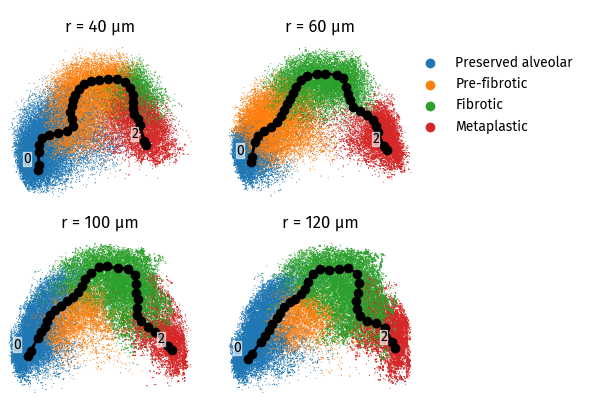

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(6,4))
axes = axes.flatten()
fig.subplots_adjust(left=0, right=0.7, top=0.9, bottom=0, wspace=0.1)
for d, ax in zip([40, 60, 100, 120], axes):
    scf.pl.graph(adata_traj[d], basis="pca", color_cells="neighbor_class", s=2, ax=ax, show=False)
    ax.axis("off")
    ax.set_title(f"r = {d} µm")
    if d != 60:
        ax.legend().remove()
    else:
         ax.legend(title="", loc='upper left', bbox_to_anchor=(0.92, 0.98), edgecolor="white", labelcolor="black", markerscale=1, fontsize=10)

In [29]:
for d in [40, 60, 100, 120]:
    scf.tl.root(adata_traj[d],0)
    scf.tl.pseudotime(adata_traj[d],n_jobs=20,n_map=20,seed=1)
    t = adata_traj[d].obs["t"].values
    adata_traj[d].obs["t"] = (t - np.min(t)) / (np.max(t) - np.min(t))

node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    mappings: 100%|█████████████████████████████████████████████████████████████████████| 20/20 [00:45<00:00,  2.27s/it]
    finished (0:00:52) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    mappings: 100%|█████████████████████████████████████████████████████████████████████| 20/2

In [30]:
# reference of original continuum
# score_df_80 = pd.read_csv(f"{REV_PATH}EcNP_score_80.csv", index_col=0)
cposition = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col=0)["C_position"]

In [31]:
results = []

for d in [40, 60, 100, 120]:
    new_traj = adata_traj[d].obs["t"].copy()
    idx = new_traj.index.intersection(cposition.index)

    original = cposition.loc[idx]
    new_traj = new_traj.loc[idx]

    rho, p = spearmanr(original, new_traj)

    results.append({
        "radius": d,
        "n_cells": len(idx),
        "Spearman_rho": rho,
        "MAE": np.mean(np.abs(original - new_traj)),
        "Median_AE": np.median(np.abs(original - new_traj)),
    })

new_traj_summary = pd.DataFrame(results).set_index("radius")


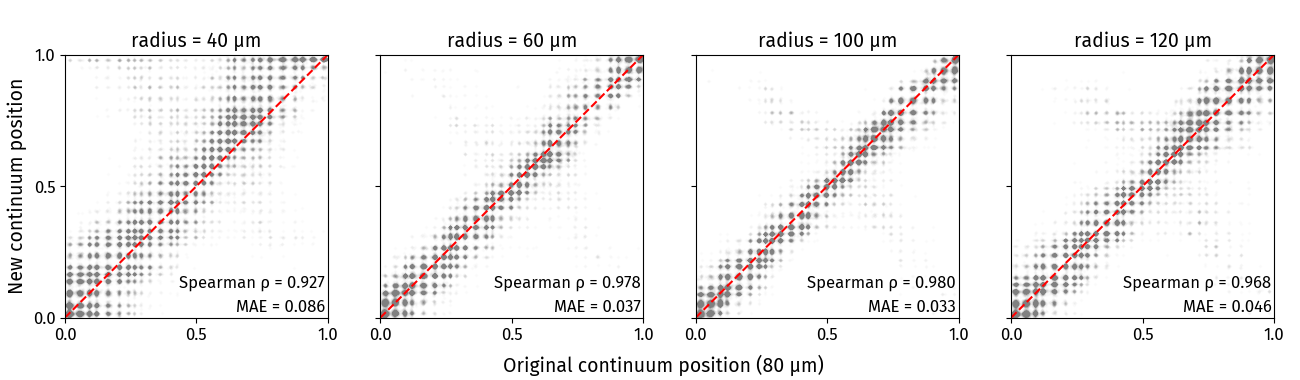

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(13,3.8))
fig.subplots_adjust(left=0.05, right=0.98, bottom=0.03, top=0.99)
axes = axes.flatten()

for n, (d, ax) in enumerate(zip([40, 60, 100, 120], axes)):
    new_traj = adata_traj[d].obs["t"].copy()
    idx = new_traj.index.intersection(cposition.index)

    x = cposition.loc[idx]
    y = new_traj.loc[idx]

    ax.scatter(x, y, s=2, alpha=0.02, c="grey")
    ax.plot([0, 1], [0, 1], linestyle="--", c="red")
    ax.set_aspect("equal")
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.set_xticks([0,0.5,1.0])

    if n > 0:
        ax.set_yticks([0, 0.5, 1.0], labels=[])
    else:
        ax.set_yticks([0,0.5,1.0])
        ax.set_ylabel("New continuum position", fontsize=14)

    ax.set_title(f"radius = {d} µm", fontsize=14)
    ax.tick_params("both", labelsize=12)
    ax.text(s=f"Spearman ρ = {new_traj_summary.loc[d, "Spearman_rho"]:.3f}", x=0.99, y=0.1, ha="right", va="bottom", fontsize=12)
    ax.text(s=f"MAE = {new_traj_summary.loc[d, "MAE"]:.3f}", x=0.99, y=0.01, ha="right", va="bottom", fontsize=12)

fig.text(s="Original continuum position (80 µm)", x=0.51, y=0.01, fontsize=14, ha="center", va="bottom")
fig.savefig(f"{REV_PATH}101_original_vs_new_continuum_scatter.png", dpi=500)
plt.show()

In [52]:
temp_list = []

for d in distance:
    if d != 80:
        temp = adata_traj[d].obs["t"].copy()
    else:
        temp= cposition.copy()
        temp = temp.rename("t")

    temp = pd.merge(
        temp,
        adata.obs[["sample"]],
        left_index=True,
        right_index=True,
        how="left"
    )
    temp["radius"] = d
    temp_list.append(temp)

plot_df = pd.concat(temp_list)

In [53]:
sample_summary = (
    plot_df
    .groupby(["radius", "sample"])["t"]
    .agg(["mean", "median"])
    .reset_index()
)

/tmp/ipykernel_2351/2639087619.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["radius", "sample"])["t"]


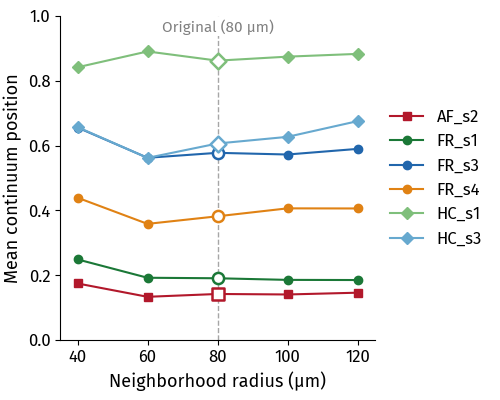

In [57]:
md_mn = "mean"

fig, ax = plt.subplots(figsize=(5, 4))
fig.subplots_adjust(left=0.12, bottom=0.15, right=0.75, top=0.96)

for sample in sample_summary["sample"].unique():
    if sample.startswith("AF"):
        m = "s"
    elif sample.startswith("FR"):
        m = "o"
    else:
        m = "D"

    x = sample_summary[sample_summary["sample"] == sample].sort_values("radius")

    color = SAMPLE_COLORS[sample]

    # All radii: sample-specific line and filled markers
    ax.plot(
        x["radius"],
        x[md_mn],
        marker=m,
        markersize=6,
        linewidth=1.5,
        color=color,
        markerfacecolor=color,
        markeredgecolor=color,
        label=sample,
        zorder=2
    )

    # Original 80 µm: open marker
    ref = x[x["radius"] == 80]

    if not ref.empty:
        ax.scatter(
            ref["radius"],
            ref[md_mn],
            marker=m,
            s=65,
            facecolors="white",
            edgecolors=color,
            linewidths=1.8,
            zorder=5
        )

# Original reference
ax.axvline(
    80,
    color="grey",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    zorder=0
)

ax.text(
    80, 0.99,
    "Original (80 µm)",
    ha="center",
    va="top",
    fontsize=11,
    color="grey",
    bbox=dict(facecolor="white", edgecolor="none", pad=1)
)

ax.set_xlim(35, 125)
ax.set_ylim(0, 1.0)
ax.set_xticks([40, 60, 80, 100, 120])
ax.tick_params("both", labelsize=12)
ax.set_xlabel("Neighborhood radius (µm)", fontsize=13)
ax.set_ylabel(f"{md_mn.capitalize()} continuum position", fontsize=13)

ax.legend(title="", bbox_to_anchor=(1, 0.5), loc="center left", edgecolor="none", fontsize=12)

ax.spines[["top", "right"]].set_visible(False)

fig.savefig(f"{REV_PATH}101_new_continuum_sample_{md_mn}.png", dpi=500, bbox_inches="tight")

plt.show()

In [58]:
# Source Data for mean continuum position across radii

source_data = (
    sample_summary[["sample", "radius", "mean"]]
    .copy()
    .rename(columns={
        "radius": "neighborhood_radius_um",
        "mean": "mean_continuum_position"
    })
)

source_data["analysis"] = np.where(
    source_data["neighborhood_radius_um"] == 80,
    "Original",
    "Reconstructed"
)

source_data = source_data.sort_values(
    ["sample", "neighborhood_radius_um"]
).reset_index(drop=True)

source_data.to_csv(
    f"{REV_PATH}SourceData_ECNP_radius_sample_mean.csv",
    index=False
)

display(source_data)

,sample,neighborhood_radius_um,mean_continuum_position,analysis
0,AF_s2,40,0.174500,Reconstructed
1,AF_s2,60,0.133310,Reconstructed
2,AF_s2,80,0.142050,Original
3,AF_s2,100,0.140515,Reconstructed
4,AF_s2,120,0.145998,Reconstructed
5,FR_s1,40,0.248775,Reconstructed
6,FR_s1,60,0.192117,Reconstructed
7,FR_s1,80,0.190540,Original
8,FR_s1,100,0.185556,Reconstructed
9,FR_s1,120,0.185075,Reconstructed
